# Which vision model makes the best inspector?

Every model as the verifier, on the **same** scenes, prompt and scorer:
- **Simulated:** the 120 held-out rendered scenes (`runs/bench/feval_v1__*`).
- **Real:** 275 real factory photos from MVTec AD (`runs/bench/mvtec__*`), scored as "damaged part flagged / good part left alone".

Run the cells top to bottom; nothing here costs anything except the last cell, which is off
unless you set `RUN_MODEL`. Kernel: "Python (selfheal .venv)". Long batches: run
`eval/compare_models.py` in the background instead (see its header).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "eval"))
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import compare_models

rows = compare_models.table()
print(len(rows), "models with results")

9 models with results


## 1. Simulated held-out scenes: correct, false alarms, missed faults

In [2]:
sim = sorted([r for r in rows if "sim_correct" in r], key=lambda r: -r["sim_correct"])
lines = ["| Model | Correct | False alarms (good parts) | Missed faults | Unreadable replies |", "|---|---|---|---|---|"]
for r in sim:
    lines.append(f"| {r['model']} | **{r['sim_correct']}%** | {r['sim_false_alarms']}% | {r['sim_missed']}% | {r['sim_unreadable']} |")
display(Markdown("\n".join(lines)))

| Model | Correct | False alarms (good parts) | Missed faults | Unreadable replies |
|---|---|---|---|---|
| nvidia/Cosmos-Reason1-7B + LoRA (ours) | **94.2%** | 25.0% | 0.0% | 0 |
| Cosmos-Reason1-7B + LoRA, 4-bit on T4 | **93.3%** | 20.0% | 2.0% | 0 |
| MiniMaxAI/MiniMax-M3 | **75.8%** | 5.0% | 16.0% | 7 |
| moonshotai/Kimi-K3 | **72.5%** | 5.0% | 16.0% | 15 |
| deepseek-ai/DeepSeek-V4.1-Flash | **68.3%** | 10.0% | 33.0% | 2 |
| Qwen/Qwen3.8-27B | **66.7%** | 0.0% | 22.0% | 17 |
| google/gemma-3-27b-it | **48.3%** | 0.0% | 52.0% | 0 |
| nvidia/Nemotron-Nano-12B-v2-VL (zero-shot) | **38.3%** | 55.0% | 38.0% | 0 |
| nvidia/Cosmos-Reason1-7B (base, zero-shot) | **21.7%** | 50.0% | 30.0% | 0 |

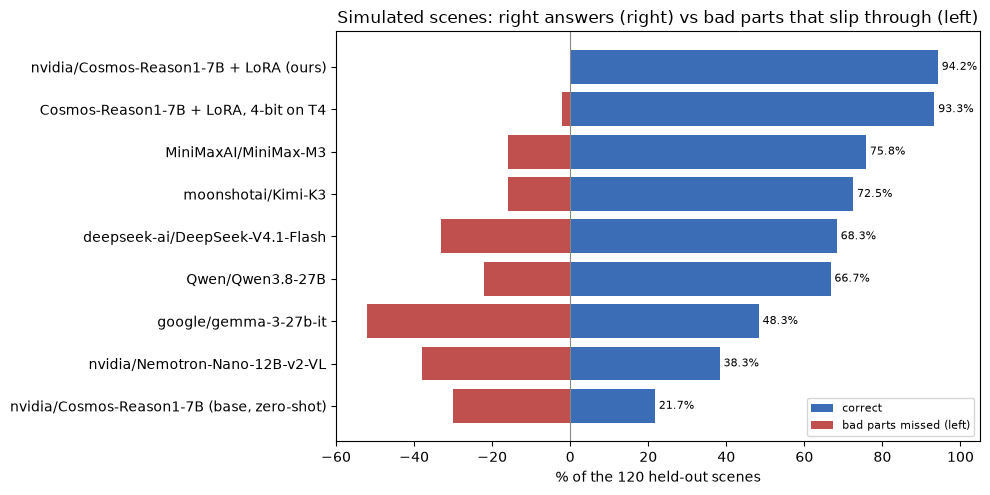

In [3]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(sim) + 1))
names = [r["model"].replace(" (zero-shot)", "") for r in sim][::-1]
ax.barh(names, [r["sim_correct"] for r in sim][::-1], color="#3a6db5", label="correct")
ax.barh(names, [-r["sim_missed"] for r in sim][::-1], color="#c0504d", label="bad parts missed (left)")
for i, r in enumerate(sim[::-1]):
    ax.text(r["sim_correct"] + 1, i, f"{r['sim_correct']}%", va="center", fontsize=8)
ax.axvline(0, color="#888", lw=0.8)
ax.set_xlim(-60, 105); ax.set_xlabel("% of the 120 held-out scenes"); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Simulated scenes: right answers (right) vs bad parts that slip through (left)")
plt.tight_layout(); plt.show()

## 2. Real factory photos (MVTec AD)

A useful inspector catches damaged parts **and** leaves good ones alone: top-left is good,
top-right means it flags everything (useless), bottom-left means it flags almost nothing.

| Model | Damaged nuts caught | Good nuts flagged | Damaged screws caught | Good screws flagged |
|---|---|---|---|---|
| Qwen/Qwen3.8-27B | 59.1% | 4.5% | 42.0% | 2.4% |
| MiniMaxAI/MiniMax-M3 | 51.6% | 0.0% | 36.1% | 2.4% |
| google/gemma-3-27b-it | 74.2% | 31.8% | 100.0% | 100.0% |
| moonshotai/Kimi-K3 | 45.2% | 4.5% | 39.5% | 0.0% |
| deepseek-ai/DeepSeek-V4.1-Flash | 28.0% | 0.0% | 10.1% | 0.0% |
| Cosmos-Reason1-7B + LoRA, 4-bit on T4 | 95.7% | 90.9% | 100.0% | 100.0% |

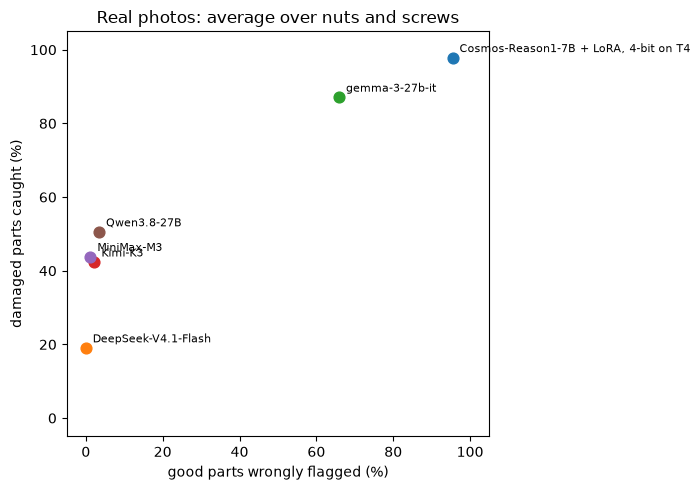

In [4]:
real = [r for r in rows if "real_metal_nut_caught" in r]
lines = ["| Model | Damaged nuts caught | Good nuts flagged | Damaged screws caught | Good screws flagged |", "|---|---|---|---|---|"]
for r in sorted(real, key=lambda r: -(r["real_metal_nut_caught"] - r["real_metal_nut_false_alarm"])):
    lines.append(f"| {r['model']} | {r['real_metal_nut_caught']}% | {r['real_metal_nut_false_alarm']}% | "
                 f"{r['real_screw_caught']}% | {r['real_screw_false_alarm']}% |")
display(Markdown("\n".join(lines)))
fig, ax = plt.subplots(figsize=(7, 5))
for r in real:
    x = (r["real_metal_nut_false_alarm"] + r["real_screw_false_alarm"]) / 2
    y = (r["real_metal_nut_caught"] + r["real_screw_caught"]) / 2
    ax.scatter(x, y, s=60)
    ax.annotate(r["model"].replace(" (zero-shot)", "").split("/")[-1], (x, y), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("good parts wrongly flagged (%)"); ax.set_ylabel("damaged parts caught (%)")
ax.set_xlim(-5, 105); ax.set_ylim(-5, 105); ax.set_title("Real photos: average over nuts and screws")
plt.tight_layout(); plt.show()

## 3. Try one model yourself (costs Token Factory credit)

Set `RUN_MODEL` to a model ID from `scripts/smoke_nemotron.py --list` and `RUN_SETS` to
`["sim"]`, `["real"]` or both. A simulated run takes a few minutes; then re-run the cells above.

In [5]:
RUN_MODEL = None          # e.g. "moonshotai/Kimi-K3"
RUN_SETS = ["sim"]

if RUN_MODEL:
    for which in RUN_SETS:
        (compare_models.sim if which == "sim" else compare_models.real)(RUN_MODEL)
else:
    print("skipped (RUN_MODEL = None)")

skipped (RUN_MODEL = None)
